# 02 — Feature engineering, models and evaluation

**Project 4 · Team T082 · Section B** — Phase 1 (classical ML).

This notebook (1) builds the feature set, (2) trains every model class on **one sensor** live so that the method is
transparent, and (3) loads the full 207-sensor results produced by `scripts/run_experiments.py` and displays the
evaluation tables and figures.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from trafficml import config as C, data, features as F, models as M, evaluate as E
pd.set_option("display.width", 140); pd.set_option("display.precision", 3)
def fig(name, width=820):
    display(Image(filename=str(C.FIGURES_DIR / f"{name}.png"), width=width))
print("project root:", ROOT)

project root: /home/claude/traffic-flow-phase1


## 1. Build features
All features are derived from the NaN-masked speed table and the sensor graph. Statistics that could leak the future (historical-average profile) are fitted on training timestamps only.

In [2]:
speed, raw, graph = data.load_all()
fs = F.build_features(speed, graph)
print("lag tensor", fs.lag.shape, "| window stats", fs.stats.shape, "| calendar", fs.time.shape, "| neighbour", fs.nbr.shape, "| targets", fs.targets.shape)
display(fs.split.summary(fs.index))
print(len(fs.local_feature_names()), "local features;", len(fs.spatial_feature_names()), "spatial features")

lag tensor (34272, 207, 12) | window stats (34272, 207, 6) | calendar (34272, 6) | neighbour (34272, 207, 8) | targets (34272, 207, 3)


,split,n_samples,start,end
0,train,23967,2012-03-01 00:55:00,2012-05-23 06:05:00
1,val,3403,2012-05-23 08:10:00,2012-06-04 03:40:00
2,test,6831,2012-06-04 05:45:00,2012-06-27 22:55:00


26 local features; 34 spatial features


In [3]:
# the design matrix of one sensor at a few timestamps (spatial variant)
n = 0
Xn = pd.DataFrame(fs.sensor_matrix(n, spatial=True), columns=fs.spatial_feature_names(), index=fs.index)
Xn.iloc[5000:5005].T

timestamp,2012-03-18 08:40:00,2012-03-18 08:45:00,2012-03-18 08:50:00,2012-03-18 08:55:00,2012-03-18 09:00:00
lag0,67.889,68.125,68.000,68.000,69.000
lag1,68.111,67.889,68.125,68.000,68.000
lag2,68.778,68.111,67.889,68.125,68.000
lag3,66.000,68.778,68.111,67.889,68.125
lag4,68.111,66.000,68.778,68.111,67.889
lag5,69.000,68.111,66.000,68.778,68.111
lag6,69.375,69.000,68.111,66.000,68.778
lag7,66.778,69.375,69.000,68.111,66.000
lag8,68.000,66.778,69.375,69.000,68.111
lag9,67.778,68.000,66.778,69.375,69.000


### Leakage checks
* targets are strictly in the future of every feature (`lag0` is the current speed, the first target is +15 min);
* the historical-average profile is estimated on `train_end` timestamps only;
* a 12-step gap separates train / validation / test so no training target overlaps a test feature window.

In [4]:
X = speed.values
assert np.allclose(np.nan_to_num(fs.lag[:, :, 0]), np.nan_to_num(X), atol=1e-4)
assert np.allclose(np.nan_to_num(fs.targets[:-12, :, 2]), np.nan_to_num(X[12:]), atol=1e-4)
assert fs.split.val[0] - fs.split.train[-1] > 12 and fs.split.test[0] - fs.split.val[-1] > 12
print("leakage checks passed")

leakage checks passed


## 2. Train every model class on one sensor (live demo)
The full experiment loops this over all 207 sensors; here we show it for the most congested sensor so the mechanics are visible.

In [5]:
import time
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

s = int(np.nanargmin(np.nanmean(X[: fs.split.train_end], axis=0)))
print("sensor", graph.sensor_ids[s], "(most congested)")
tr, va, te = fs.split.train, fs.split.val, fs.split.test
Y = fs.targets[:, s, :]; hz = fs.names["targets"]
rows = []
for spatial in (False, True):
    Xs = fs.sensor_matrix(s, spatial)
    tag = "spatial" if spatial else "local"
    # XGBoost, one model per horizon with early stopping on the validation split
    t0 = time.time(); pred = np.full((len(te), 3), np.nan)
    for h in range(3):
        ok = tr[~np.isnan(Y[tr, h])]; okv = va[~np.isnan(Y[va, h])]
        p = C.XGBParams()
        m = XGBRegressor(**p.to_dict(), early_stopping_rounds=p.early_stopping_rounds, eval_metric="mae", verbosity=0)
        m.fit(Xs[ok], Y[ok, h], eval_set=[(Xs[okv], Y[okv, h])], verbose=False)
        pred[:, h] = m.predict(Xs[te])
    rows.append({"model": f"XGB-{tag}", **{f"MAE {hz[h]}": E.masked_mae(Y[te, h], pred[:, h]) for h in range(3)}, "seconds": time.time() - t0})
    # multi-output random forest
    t0 = time.time(); ok = tr[~np.isnan(Y[tr]).any(axis=1)]
    rf = RandomForestRegressor(**C.RFParams().to_dict()).fit(Xs[ok], Y[ok]); pr = rf.predict(Xs[te])
    rows.append({"model": f"RF-{tag}", **{f"MAE {hz[h]}": E.masked_mae(Y[te, h], pr[:, h]) for h in range(3)}, "seconds": time.time() - t0})
    # ridge
    t0 = time.time(); Xi = fs.impute(Xs, s); sc = StandardScaler().fit(Xi[tr]); Z = sc.transform(Xi)
    pr = np.column_stack([Ridge(alpha=1.0).fit(Z[tr[~np.isnan(Y[tr, h])]], Y[tr[~np.isnan(Y[tr, h])], h]).predict(Z[te]) for h in range(3)])
    rows.append({"model": f"Ridge-{tag}", **{f"MAE {hz[h]}": E.masked_mae(Y[te, h], pr[:, h]) for h in range(3)}, "seconds": time.time() - t0})
for name, out in (("HA", M.historical_average(fs)), ("Persistence", M.persistence(fs))):
    rows.append({"model": name, **{f"MAE {hz[h]}": E.masked_mae(Y[te, h], out.test_pred[:, s, h]) for h in range(3)}, "seconds": 0})
pd.DataFrame(rows).set_index("model").round(3)

sensor 771667 (most congested)


,MAE 15min,MAE 30min,MAE 60min,seconds
model,,,,
XGB-local,1.603,1.716,1.798,3.275
RF-local,1.605,1.718,1.803,8.446
Ridge-local,1.678,1.843,2.017,0.256
XGB-spatial,1.589,1.707,1.798,2.978
RF-spatial,1.590,1.696,1.785,11.713
Ridge-spatial,1.670,1.833,1.997,0.057
HA,1.891,1.891,1.893,0.000
Persistence,1.992,2.280,2.687,0.000


## 3. Full results (all 207 sensors)
Produced by `python scripts/run_experiments.py`; metrics are masked (outage targets excluded) and computed on the test split (4–27 June 2012).

In [6]:
hm = pd.read_csv(C.RESULTS_DIR / "metrics_horizon.csv")
display(Markdown("**Test MAE (mph)**")); display(hm.pivot(index="model", columns="horizon", values="MAE").round(3))
display(Markdown("**Test RMSE (mph)**")); display(hm.pivot(index="model", columns="horizon", values="RMSE").round(3))
display(Markdown("**Test MAPE (%)**")); display(hm.pivot(index="model", columns="horizon", values="MAPE").round(2))
display(Markdown("**Training wall-clock (s)**")); display(hm.groupby("model").fit_seconds.first().round(0).to_frame())

**Test MAE (mph)**

horizon,15min,30min,60min,average
model,,,,
HA,4.193,4.193,4.194,4.193
Persistence,3.485,4.180,5.333,4.333
RF-local,2.974,3.415,3.865,3.418
RF-spatial,2.872,3.309,3.810,3.331
Ridge-local,3.229,3.924,4.960,4.038
XGB-local,2.991,3.437,3.851,3.426
XGB-spatial,2.867,3.323,3.783,3.324


**Test RMSE (mph)**

horizon,15min,30min,60min,average
model,,,,
HA,7.862,7.862,7.862,7.862
Persistence,6.382,7.997,10.269,8.369
RF-local,5.441,6.380,7.245,6.398
RF-spatial,5.159,6.093,7.062,6.154
Ridge-local,5.746,6.982,8.442,7.142
XGB-local,5.517,6.454,7.258,6.449
XGB-spatial,5.175,6.155,7.070,6.182


**Test MAPE (%)**

horizon,15min,30min,60min,average
model,,,,
HA,13.06,13.06,13.06,13.06
Persistence,8.58,10.79,14.42,11.27
RF-local,8.15,9.88,11.66,9.90
RF-spatial,7.68,9.35,11.30,9.44
Ridge-local,8.83,11.41,15.05,11.76
XGB-local,8.24,9.97,11.61,9.94
XGB-spatial,7.65,9.41,11.22,9.42


**Training wall-clock (s)**

,fit_seconds
model,
HA,0.0
Persistence,0.0
RF-local,1422.0
RF-spatial,2114.0
Ridge-local,7.0
XGB-local,558.0
XGB-spatial,694.0


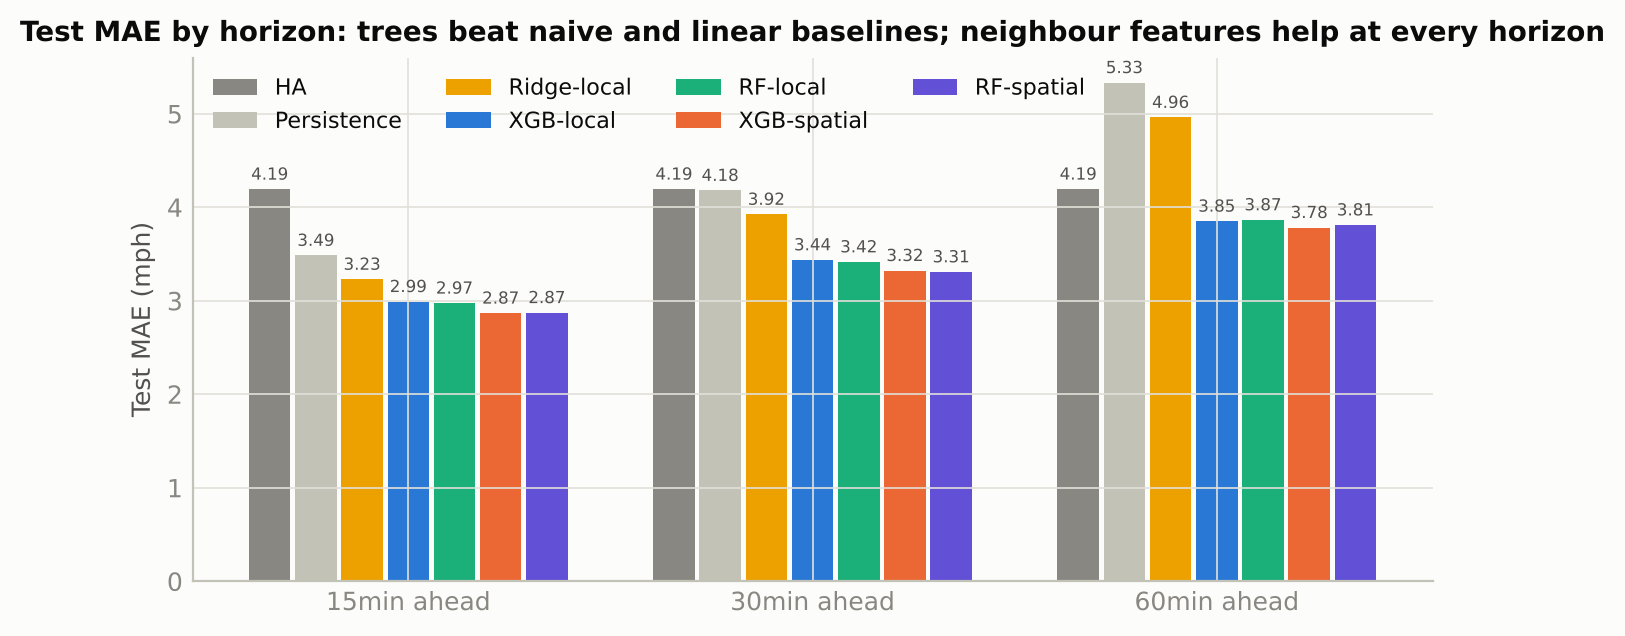

In [7]:
fig("fig_res_mae_by_horizon")

### Validation split (used for early stopping / model selection)
The ranking on validation matches the ranking on test, so test numbers are not the product of test-set tuning.

In [8]:
vm = pd.read_csv(C.RESULTS_DIR / "metrics_validation.csv")
vm.pivot(index="model", columns="horizon", values="MAE").round(3)

horizon,15min,30min,60min,average
model,,,,
HA,4.320,4.316,4.305,4.314
Persistence,3.206,3.795,4.753,3.918
RF-local,2.862,3.317,3.791,3.324
RF-spatial,2.730,3.163,3.686,3.193
Ridge-local,3.105,3.820,4.867,3.931
XGB-local,2.848,3.309,3.745,3.301
XGB-spatial,2.703,3.155,3.626,3.162


### Peak vs off-peak
Weekday 07–10 h and 16–19 h target times vs everything else.

MAE            RMSE             MAPE        
period      off-peak   peak off-peak    peak off-peak    peak
model                                                        
HA             3.604  6.528    6.994  10.624   10.170  24.516
Persistence    4.713  7.786    9.225  13.640   11.218  27.103
RF-local       3.350  5.904    6.424   9.845    9.176  21.492
RF-spatial     3.327  5.726    6.289   9.526    8.978  20.500
Ridge-local    4.285  7.636    7.252  12.049   10.995  31.128
XGB-local      3.345  5.855    6.453   9.817    9.185  21.223
XGB-spatial    3.307  5.666    6.310   9.500    8.949  20.199

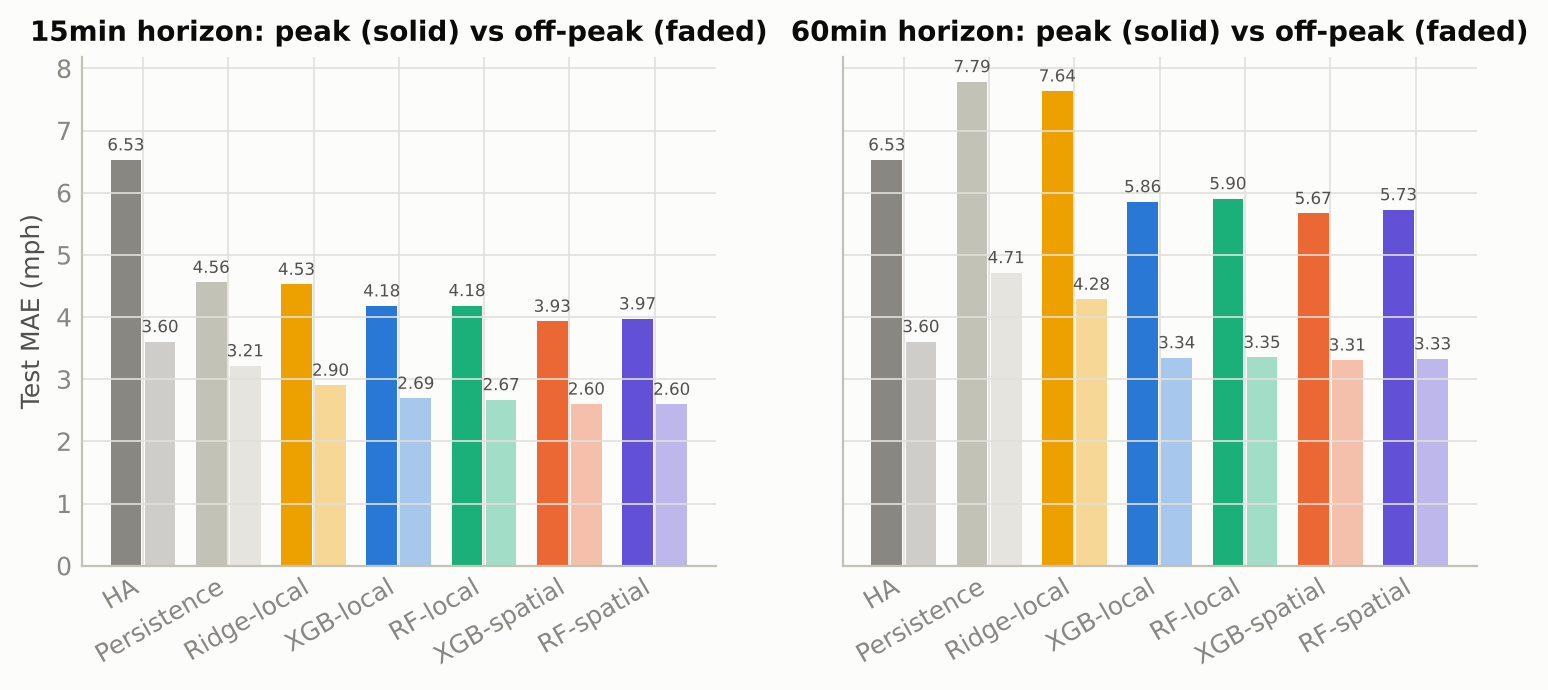

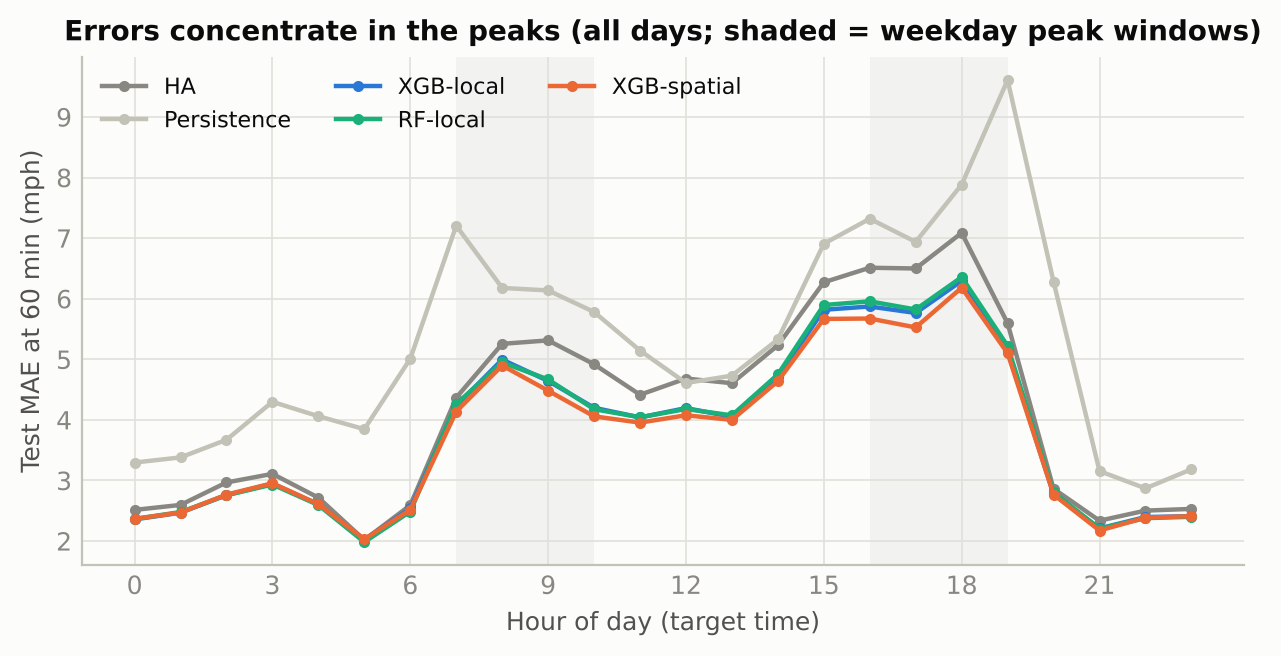

In [9]:
pk = pd.read_csv(C.RESULTS_DIR / "metrics_peak_offpeak.csv")
display(pk[pk.horizon == "60min"].pivot(index="model", columns="period", values=["MAE", "RMSE", "MAPE"]).round(3))
fig("fig_res_peak_offpeak"); fig("fig_res_mae_by_hour")

### The spatial ablation (the 'gap')
Same learner, with vs without the eight neighbour features.

XGB-local -> XGB-spatial: MAE reduction (%) {'15min': 4.1, '30min': 3.3, '60min': 1.8}
RF-local -> RF-spatial: MAE reduction (%) {'15min': 3.4, '30min': 3.1, '60min': 1.4}


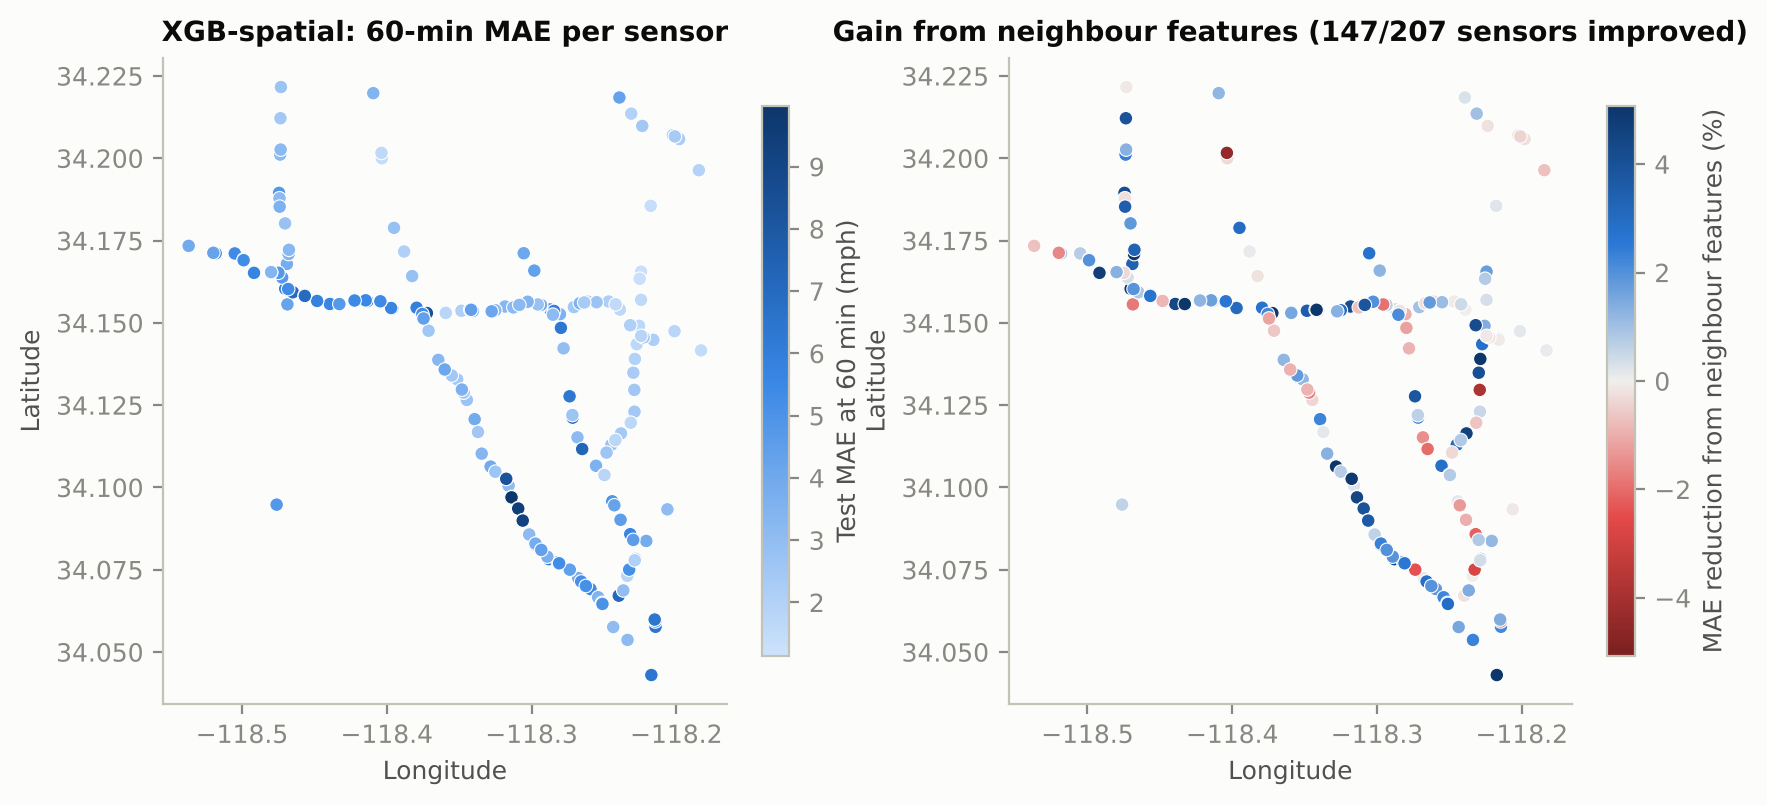

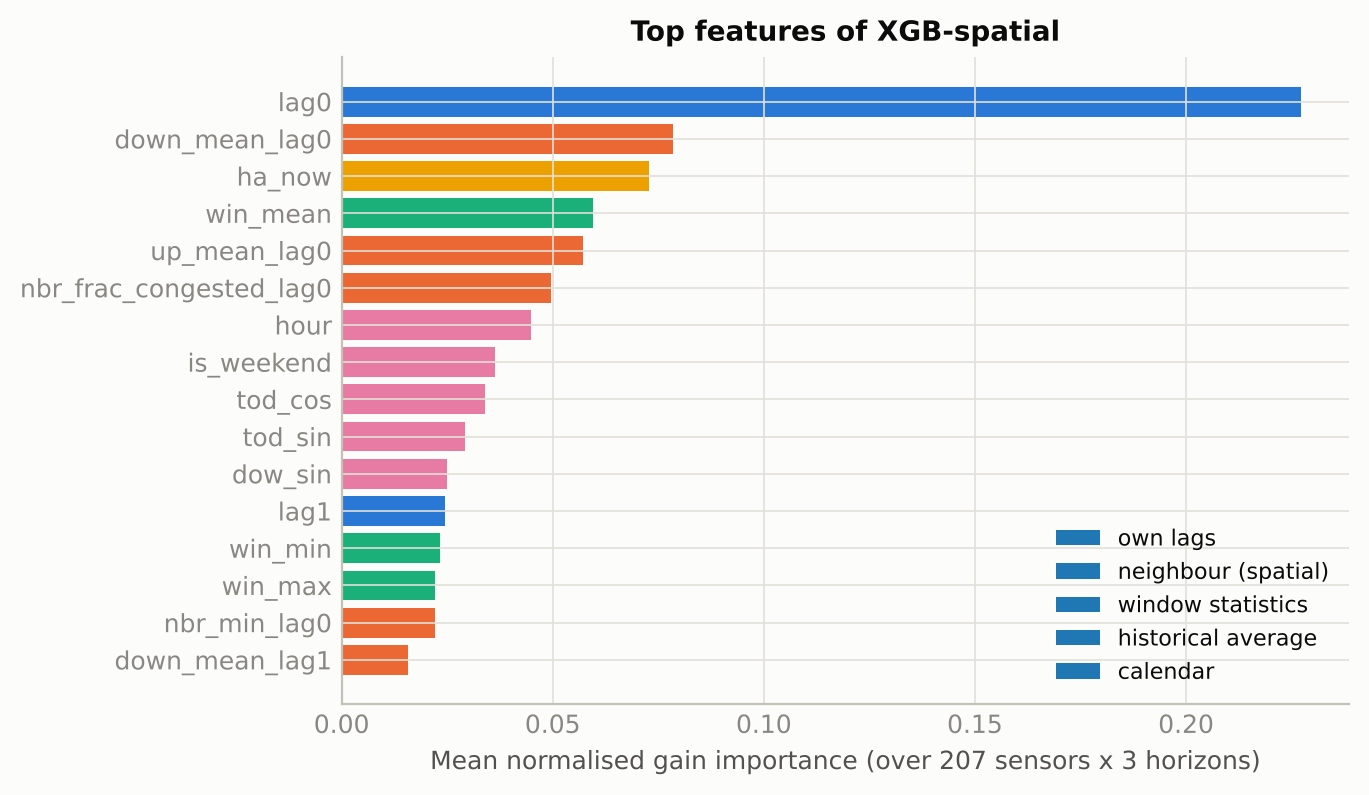

In [10]:
wide = hm[hm.horizon != "average"].pivot(index="model", columns="horizon", values="MAE")
for a, b in (("XGB-local", "XGB-spatial"), ("RF-local", "RF-spatial")):
    if a in wide.index and b in wide.index:
        print(f"{a} -> {b}: MAE reduction (%)", ((wide.loc[a] - wide.loc[b]) / wide.loc[a] * 100).round(1).to_dict())
fig("fig_res_sensor_mae_map", 900); fig("fig_res_feature_importance")

In [11]:
imp = pd.read_csv(C.RESULTS_DIR / "feature_importance.csv")
imp[imp.model == "XGB-spatial"].head(12)

,model,feature,importance
26,XGB-spatial,lag0,0.227
27,XGB-spatial,down_mean_lag0,0.078
28,XGB-spatial,ha_now,0.073
29,XGB-spatial,win_mean,0.060
30,XGB-spatial,up_mean_lag0,0.057
31,XGB-spatial,nbr_frac_congested_lag0,0.050
32,XGB-spatial,hour,0.045
33,XGB-spatial,is_weekend,0.036
34,XGB-spatial,tod_cos,0.034
35,XGB-spatial,tod_sin,0.029


### Congestion detection and congestion maps
Event: speed < 35 mph (Caltrans PeMS congestion threshold).

horizon,15min,30min,60min
model,,,
HA,0.644,0.644,0.644
Persistence,0.805,0.742,0.636
RF-local,0.807,0.751,0.690
RF-spatial,0.822,0.769,0.704
Ridge-local,0.795,0.711,0.555
XGB-local,0.802,0.747,0.693
XGB-spatial,0.821,0.766,0.709


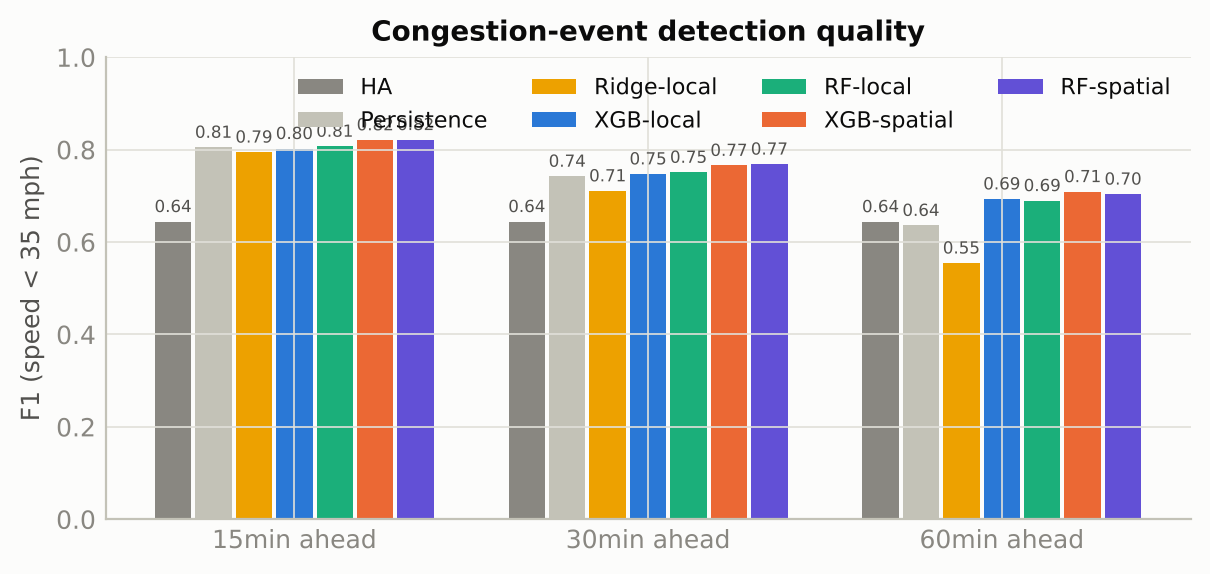

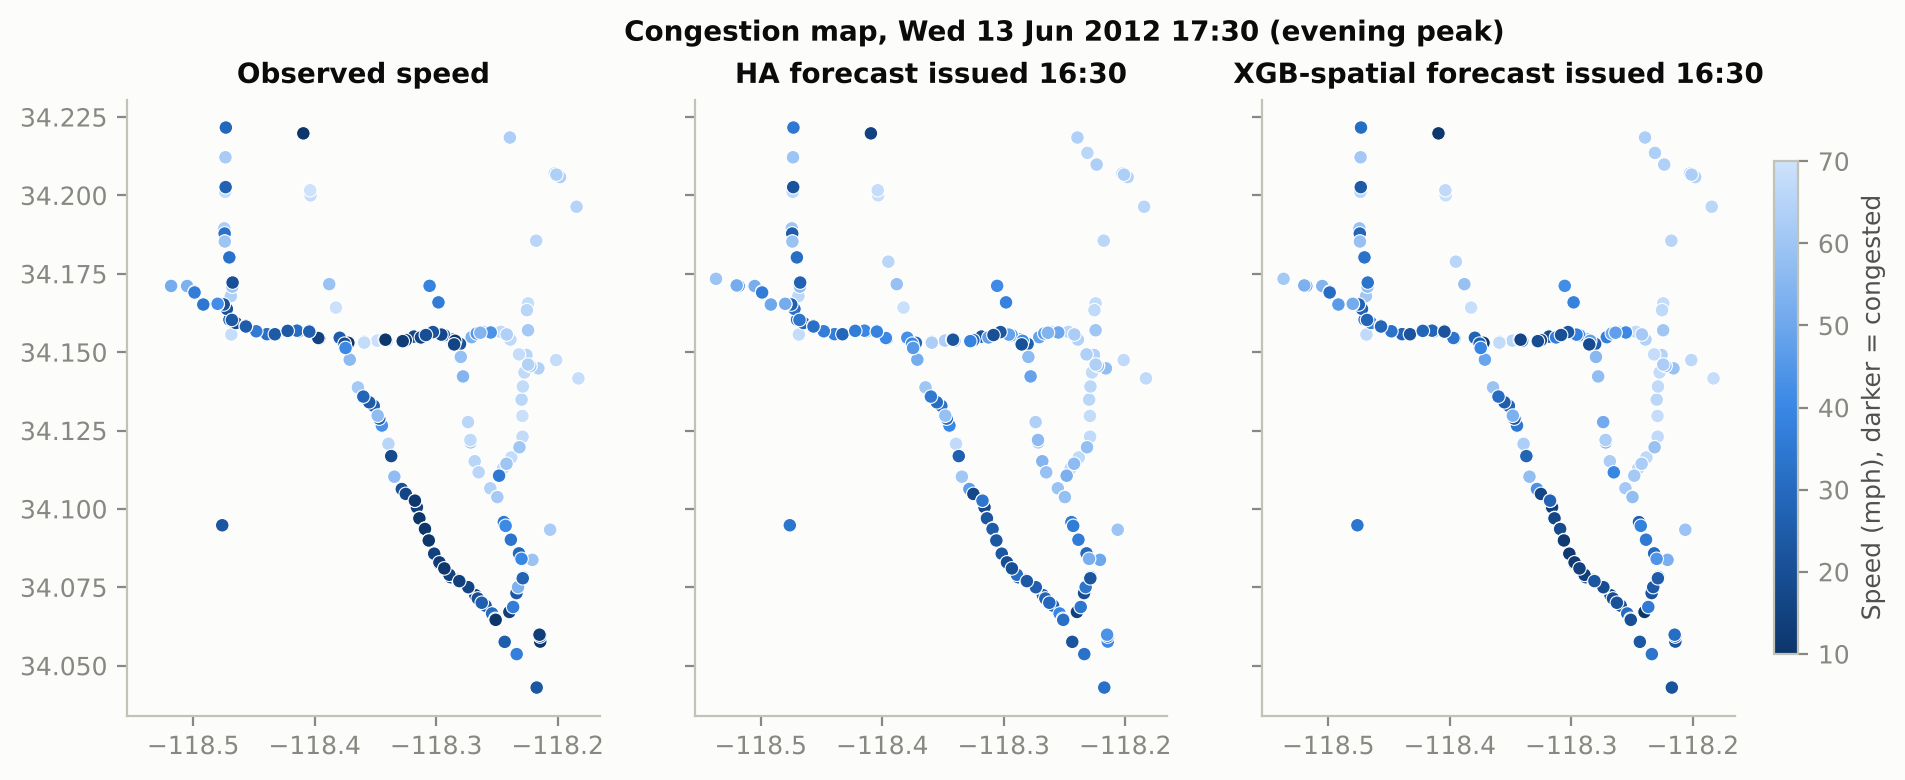

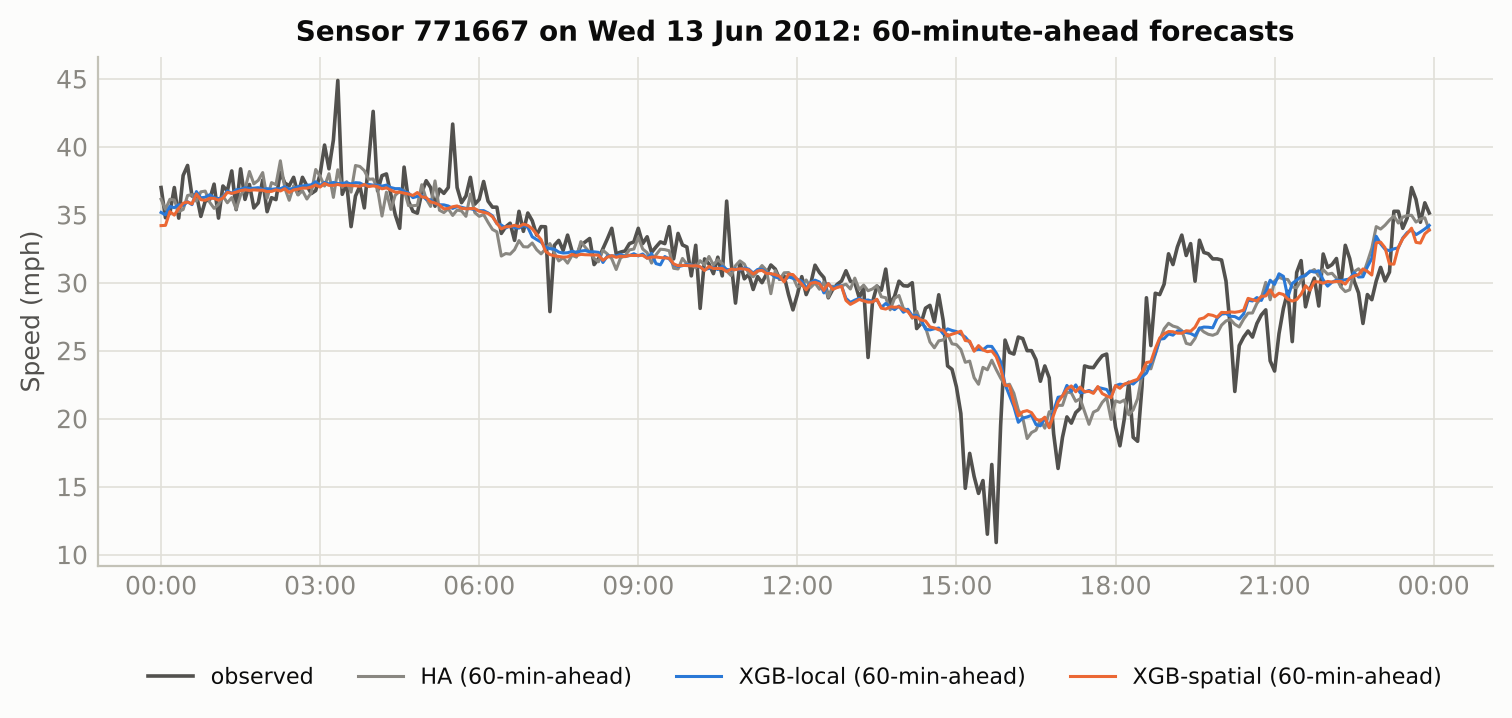

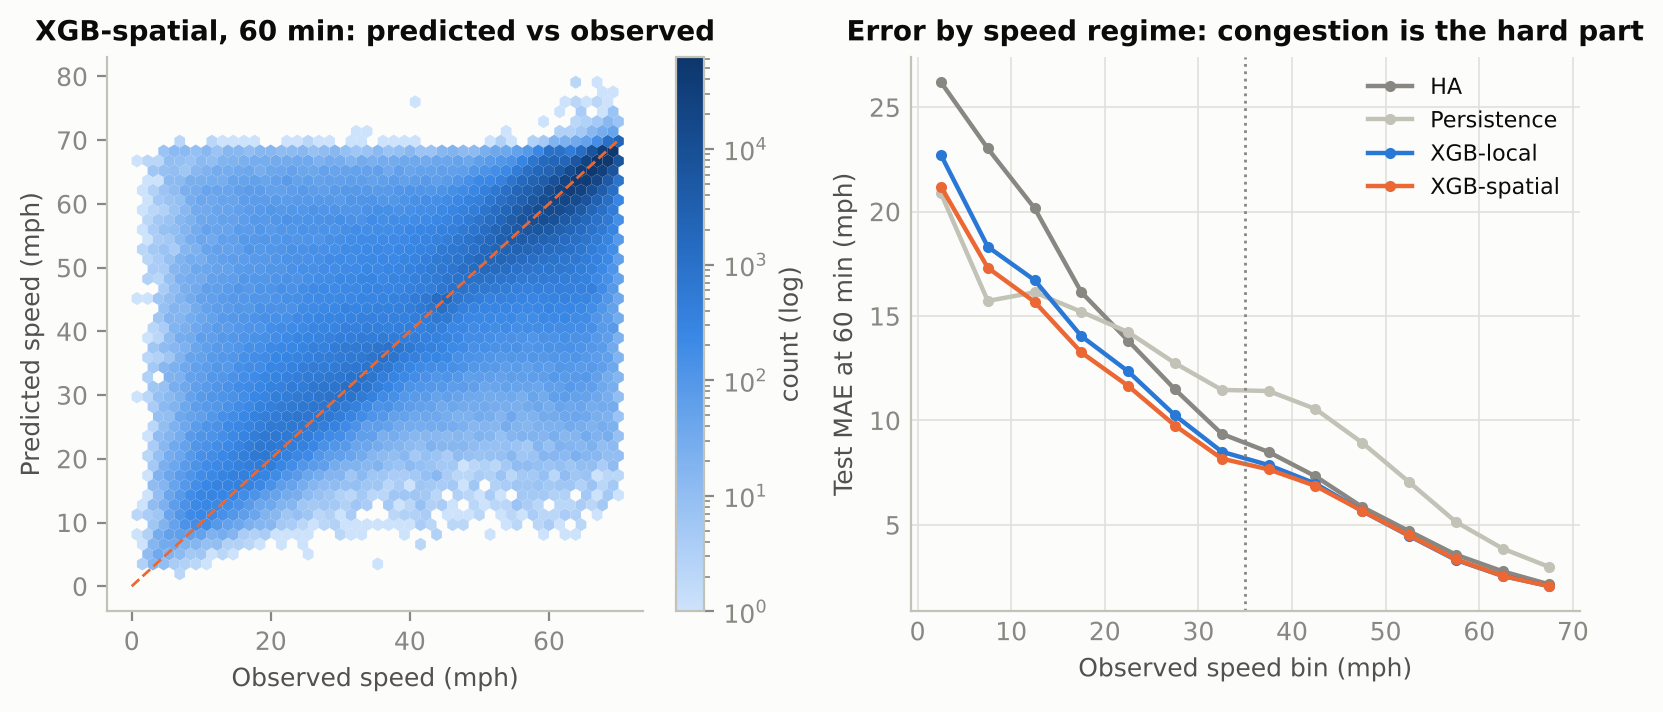

In [12]:
cg = pd.read_csv(C.RESULTS_DIR / "metrics_congestion.csv")
display(cg.pivot(index="model", columns="horizon", values="F1").round(3))
fig("fig_res_congestion_f1"); fig("fig_res_congestion_map", 950); fig("fig_res_example_forecast"); fig("fig_res_pred_vs_actual")

## 4. Conclusions

* Per-segment XGBoost is the strongest independent-segment model; the multi-output Random Forest is close.
* Adding LWR-motivated **neighbour features** improves every horizon, about three times more in the peaks than
  off-peak; the relative gain is largest at 15–30 min and fades at 60 min, as one-hop features should — a direct
  measurement of what independent-segment models miss, and the gap the multi-hop Phase 2 Graph Attention Network targets.
* Remaining error is concentrated in the congested regime (< 35 mph) and in the commute peaks.